# GIAI ĐOẠN 0 – TV3
## Phân tích giỏ hàng

**Đề tài:** Phân tích giỏ hàng siêu thị và xây dựng gợi ý mua kèm

## 1. Đọc dữ liệu đã làm sạch

In [2]:
import pandas as pd

# Đọc dữ liệu đã được TV2 làm sạch
df_tv3 = pd.read_csv("Groceries_cleaned.csv")

# Chuyển lại cột Date sang định dạng datetime (do khi lưu csv bị chuyển về chuỗi)
df_tv3["Date"] = pd.to_datetime(df_tv3["Date"])

print("Kích thước dữ liệu TV3 nhận được:", df_tv3.shape)
print("Kiểu dữ liệu các cột:")
print(df_tv3.info())

df_tv3.head()

Kích thước dữ liệu TV3 nhận được: (38006, 4)
Kiểu dữ liệu các cột:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38006 entries, 0 to 38005
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Member_number    38006 non-null  int64         
 1   Date             38006 non-null  datetime64[ns]
 2   itemDescription  38006 non-null  object        
 3   Quantity         38006 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(1)
memory usage: 1.2+ MB
None


,Member_number,Date,itemDescription,Quantity
0,1808,2015-07-21,tropical fruit,1
1,2552,2015-01-05,whole milk,1
2,2300,2015-09-19,pip fruit,1
3,1187,2015-12-12,other vegetables,1
4,3037,2015-02-01,whole milk,1


## 2. Chuẩn bị dữ liệu cho phân tích giỏ hàng

Để thực hiện phân tích giỏ hàng (Association Rule Mining), chúng ta cần chuyển dữ liệu từ định dạng "mỗi dòng một mặt hàng" sang định dạng "mỗi giao dịch một tập hợp các mặt hàng".

Chúng ta sẽ nhóm các mặt hàng theo `Member_number` và `Date` để tạo thành các "giỏ hàng" của từng khách hàng trong một ngày cụ thể.

In [3]:
# Gộp các mặt hàng thành danh sách cho mỗi giao dịch (khách hàng + ngày)
transactions = df_tv3.groupby(['Member_number', 'Date'])['itemDescription'].apply(list).reset_index()

print("Số lượng giao dịch (giỏ hàng) sau khi gộp:", len(transactions))

transactions.head()

Số lượng giao dịch (giỏ hàng) sau khi gộp: 14963


,Member_number,Date,itemDescription
0,1000,2014-06-24,"[whole milk, pastry, salty snack]"
1,1000,2015-03-15,"[sausage, whole milk, semi-finished bread, yog..."
2,1000,2015-05-27,"[soda, pickled vegetables]"
3,1000,2015-07-24,"[canned beer, misc. beverages]"
4,1000,2015-11-25,"[sausage, hygiene articles]"


## 3. Tổng kết các giao dịch

Dữ liệu `transactions` hiện đã có dạng mỗi hàng là một giao dịch mua hàng, với cột `itemDescription` chứa danh sách các mặt hàng trong giao dịch đó. Đây là định dạng phù hợp để áp dụng các thuật toán khai phá luật kết hợp.

In [4]:
# Hiển thị một vài giao dịch mẫu
for i in range(5):
    if i < len(transactions):
        print(f"Giao dịch {i+1} (Khách hàng {transactions['Member_number'].iloc[i]}, Ngày {transactions['Date'].iloc[i].date()}):\n{transactions['itemDescription'].iloc[i]}\n")

Giao dịch 1 (Khách hàng 1000, Ngày 2014-06-24):
['whole milk', 'pastry', 'salty snack']

Giao dịch 2 (Khách hàng 1000, Ngày 2015-03-15):
['sausage', 'whole milk', 'semi-finished bread', 'yogurt']

Giao dịch 3 (Khách hàng 1000, Ngày 2015-05-27):
['soda', 'pickled vegetables']

Giao dịch 4 (Khách hàng 1000, Ngày 2015-07-24):
['canned beer', 'misc. beverages']

Giao dịch 5 (Khách hàng 1000, Ngày 2015-11-25):
['sausage', 'hygiene articles']



## 4. Chuyển đổi sang Dạng Giao dịch và Ma trận One-Hot

Để thống nhất và dễ dàng theo dõi các giao dịch, chúng ta sẽ tạo một `Transaction_ID` duy nhất cho mỗi giao dịch (kết hợp `Member_number` và `Date`).

Sau đó, để chuẩn bị dữ liệu cho các thuật toán khai phá luật kết hợp như Apriori hay FP-Growth, chúng ta cần chuyển đổi danh sách các mặt hàng trong mỗi giao dịch thành một ma trận One-Hot Encoding. Trong ma trận này, mỗi hàng là một giao dịch, và mỗi cột đại diện cho một mặt hàng. Giá trị 1 cho biết mặt hàng đó có trong giao dịch, và 0 nếu không có.

In [5]:
# Cài đặt thư viện mlxtend nếu chưa có
%pip install mlxtend

# Tạo Transaction_ID
df_trans = transactions.copy()
df_trans['Transaction_ID'] = df_trans['Member_number'].astype(str) + '_' + df_trans['Date'].dt.strftime('%Y%m%d')

df_trans.head()

,Member_number,Date,itemDescription,Transaction_ID
0,1000,2014-06-24,"[whole milk, pastry, salty snack]",1000_20140624
1,1000,2015-03-15,"[sausage, whole milk, semi-finished bread, yog...",1000_20150315
2,1000,2015-05-27,"[soda, pickled vegetables]",1000_20150527
3,1000,2015-07-24,"[canned beer, misc. beverages]",1000_20150724
4,1000,2015-11-25,"[sausage, hygiene articles]",1000_20151125


In [6]:
from mlxtend.preprocessing import TransactionEncoder

# Khởi tạo TransactionEncoder
te = TransactionEncoder()

# Chuyển đổi danh sách các mặt hàng sang dạng One-Hot Encoding
te_ary = te.fit(df_trans['itemDescription']).transform(df_trans['itemDescription'])
df_onehot = pd.DataFrame(te_ary, columns=te.columns_)

# Gắn Transaction_ID vào ma trận One-Hot
df_onehot.insert(0, 'Transaction_ID', df_trans['Transaction_ID'])

print("Kích thước ma trận One-Hot:", df_onehot.shape)
print("5 dòng đầu của ma trận One-Hot:")
df_onehot.head()

Kích thước ma trận One-Hot: (14963, 168)
5 dòng đầu của ma trận One-Hot:


,Transaction_ID,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,beverages,...,uht-milk,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,1000_20140624,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,1000_20150315,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
2,1000_20150527,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,1000_20150724,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1000_20151125,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


## 5. Trực quan hóa dữ liệu khám phá (EDA)

### Biểu đồ 1: Phân bố kích thước giỏ hàng (Basket Size Distribution)

Biểu đồ này cho thấy số lượng mặt hàng (items) trung bình trong mỗi giao dịch (giỏ hàng). Nó giúp chúng ta hiểu được hành vi mua sắm của khách hàng, liệu họ có thường mua nhiều mặt hàng cùng lúc hay không.

/tmp/ipykernel_1597/2305347356.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=basket_sizes, palette='viridis')


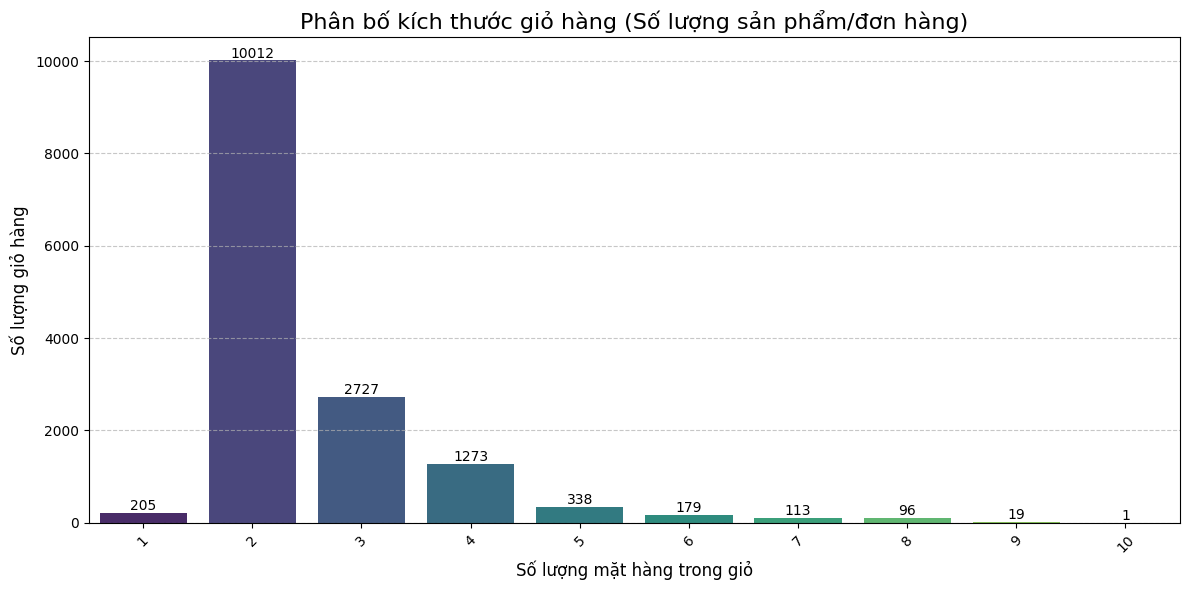

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tính toán kích thước của mỗi giỏ hàng
basket_sizes = df_trans['itemDescription'].apply(len)

# Tạo biểu đồ phân bố kích thước giỏ hàng
plt.figure(figsize=(12, 6))
sns.countplot(x=basket_sizes, palette='viridis')

plt.title('Phân bố kích thước giỏ hàng (Số lượng sản phẩm/đơn hàng)', fontsize=16)
plt.xlabel('Số lượng mặt hàng trong giỏ', fontsize=12)
plt.ylabel('Số lượng giỏ hàng', fontsize=12)

# Ghi chú số lượng trên đầu mỗi cột
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}',
                       (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center',
                       xytext=(0, 5), textcoords='offset points', fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Biểu đồ 2: Top 15 mặt hàng được mua nhiều nhất

Biểu đồ này hiển thị 15 mặt hàng xuất hiện thường xuyên nhất trong tổng số các giao dịch. Đây là những sản phẩm 'hot' và có thể là điểm khởi đầu tốt để phân tích sâu hơn hoặc đặt trong các chương trình khuyến mãi.

/tmp/ipykernel_1597/1808719803.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_15_items.values, y=top_15_items.index, palette='crest')


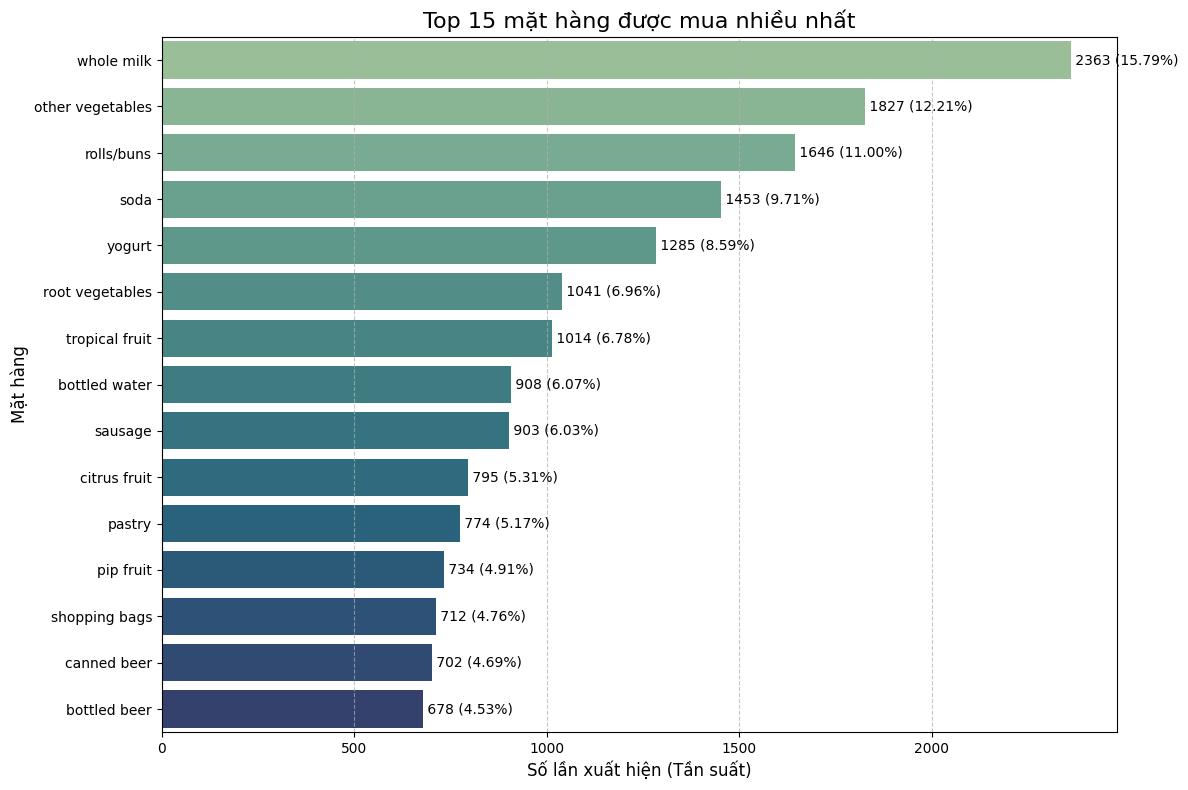

In [8]:
# Tính toán tần suất xuất hiện của mỗi mặt hàng
item_counts = df_onehot.drop(columns=['Transaction_ID']).sum().sort_values(ascending=False)

# Tính toán tỷ lệ Support đơn lẻ (%)
total_transactions = len(df_onehot)
item_support = (item_counts / total_transactions * 100).round(2)

# Lấy Top 15 mặt hàng
top_15_items = item_counts.head(15)
top_15_support = item_support.loc[top_15_items.index]

# Tạo biểu đồ cột ngang
plt.figure(figsize=(12, 8))
sns.barplot(x=top_15_items.values, y=top_15_items.index, palette='crest')

plt.title('Top 15 mặt hàng được mua nhiều nhất', fontsize=16)
plt.xlabel('Số lần xuất hiện (Tần suất)', fontsize=12)
plt.ylabel('Mặt hàng', fontsize=12)

# Hiển thị tần suất và tỷ lệ Support trên mỗi cột
for index, value in enumerate(top_15_items):
    plt.text(value, index, f' {value} ({top_15_support.iloc[index]:.2f}%)', va='center', fontsize=10)

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Biểu đồ 3: Số lượng giỏ hàng theo tháng (2014–2015)

Biểu đồ này thống kê số lượng giao dịch (giỏ hàng) được thực hiện qua từng tháng từ năm 2014 đến năm 2015 nhằm tìm ra xu hướng mua sắm theo thời gian và các mốc thời gian cao điểm/thấp điểm.

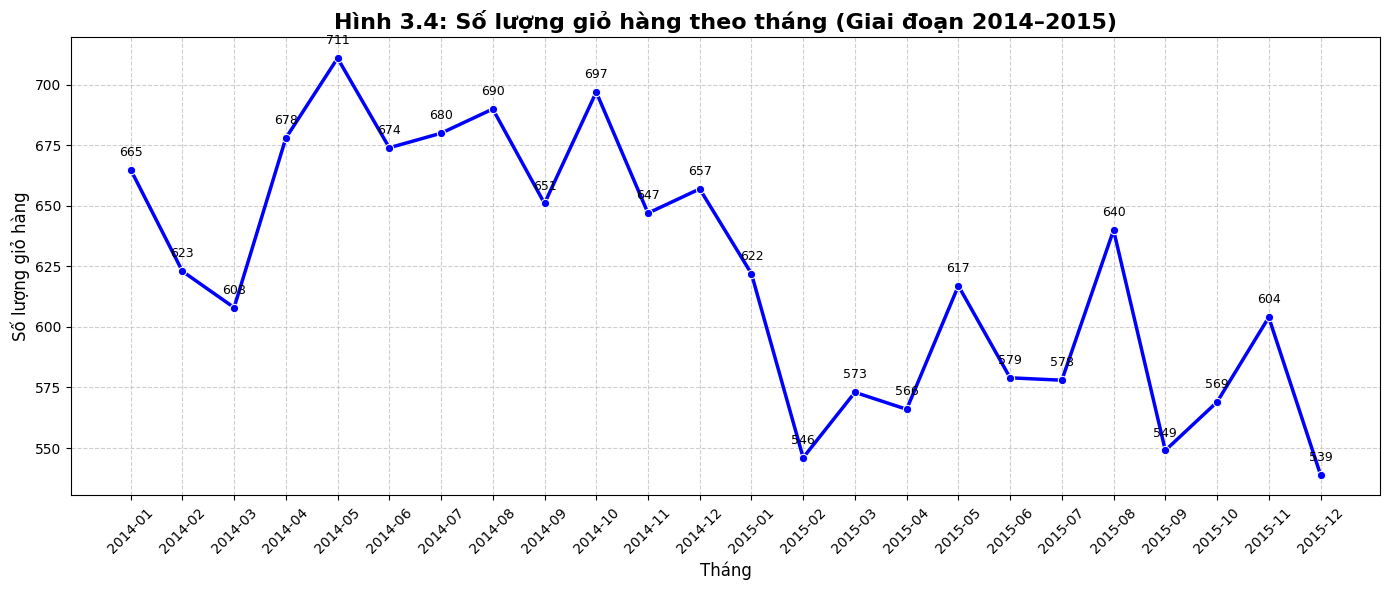

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tạo cột Năm-Tháng từ thuộc tính Date
df_trans['Year_Month'] = df_trans['Date'].dt.to_period('M')

# Đếm số lượng giao dịch theo từng tháng
monthly_baskets = df_trans.groupby('Year_Month').size().reset_index(name='Basket_Count')
monthly_baskets['Year_Month_Str'] = monthly_baskets['Year_Month'].astype(str)

# Vẽ biểu đồ đường thể hiện xu hướng
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_baskets, x='Year_Month_Str', y='Basket_Count', marker='o', color='b', linewidth=2.5)

plt.title('Hình 3.4: Số lượng giỏ hàng theo tháng (Giai đoạn 2014–2015)', fontsize=16, fontweight='bold')
plt.xlabel('Tháng', fontsize=12)
plt.ylabel('Số lượng giỏ hàng', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)

# Hiển thị giá trị cụ thể trên từng nút điểm
for i, row in monthly_baskets.iterrows():
    plt.annotate(f"{row['Basket_Count']}",
                 (row['Year_Month_Str'], row['Basket_Count']),
                 textcoords="offset points",
                 xytext=(0,10),
                 ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 6. Xuất file bàn giao

Sau khi đã biến đổi và khám phá dữ liệu, chúng ta sẽ xuất các file theo định dạng chuẩn bị cho các bước tiếp theo (áp dụng thuật toán khai phá luật kết hợp).

In [9]:
# 1. Groceries_basket_onehot.csv: Ma trận One-Hot
df_onehot.to_csv('Groceries_basket_onehot.csv', index=False)
print("Đã lưu file: Groceries_basket_onehot.csv")

# 2. Groceries_transactions.json: Dạng danh sách mảng Python (list of lists)
import json
with open('Groceries_transactions.json', 'w', encoding='utf-8') as f:
    json.dump(df_trans['itemDescription'].tolist(), f, ensure_ascii=False, indent=4)
print("Đã lưu file: Groceries_transactions.json")

# 3. Groceries_transactions_list.csv: Dạng bảng lưu giỏ hàng cách nhau bởi dấu phẩy
df_trans['item_list_str'] = df_trans['itemDescription'].apply(lambda x: ', '.join(x))
df_trans[['Transaction_ID', 'item_list_str']].to_csv('Groceries_transactions_list.csv', index=False)
print("Đã lưu file: Groceries_transactions_list.csv")

print("\nHoàn thành bàn giao dữ liệu cho bước tiếp theo ")

Đã lưu file: Groceries_basket_onehot.csv
Đã lưu file: Groceries_transactions.json
Đã lưu file: Groceries_transactions_list.csv

Hoàn thành bàn giao dữ liệu cho bước tiếp theo 


## 7. Ghi chú bàn giao cho giai đoạn tiếp theo

Để bàn giao cho giai đoạn tiếp theo thực hiện 'Khai phá luật kết hợp', TV3 đã cung cấp các file dữ liệu sau:

- **`Groceries_basket_onehot.csv`**: Chứa ma trận One-Hot Encoding của các giao dịch, sẵn sàng làm đầu vào cho thuật toán Apriori/FP-Growth. Mỗi hàng là một giao dịch, mỗi cột là một mặt hàng (0: không có, 1: có).
- **`Groceries_transactions.json`**: Chứa danh sách các giao dịch dưới dạng `list of lists` (list Python), mỗi list con là các mặt hàng trong một giỏ hàng. Đây là định dạng phổ biến cho nhiều thư viện khai phá luật kết hợp.
- **`Groceries_transactions_list.csv`**: Là phiên bản dạng bảng của các giao dịch, trong đó các mặt hàng trong cùng một giỏ hàng được nối với nhau bằng dấu phẩy trong một cột.

Dữ liệu này đã được chuẩn bị để bạn có thể áp dụng trực tiếp các thuật toán khai phá luật kết hợp và tìm ra các quy tắc mua kèm tiềm năng.